# Statistical Analysis of Financial Return Distributions

## Research Objective

Investigate the empirical statistical properties of financial returns, evaluate the assumption of normally distributed returns, and explore alternative probability distributions.

## 1. Data Preparation

In [1]:
import sys
from pathlib import Path

# Locate the root of the Quantflux repository
project_root = Path.cwd().parent

# Allow JupyterLab to import our local modules
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

In [2]:
# Import standard libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Import the existing QuantFlux functions
from src.data.yfinance_provider import load_stock_data, add_market_features
from src.analysis.return_statistics import summarize_returns
from src.visualization.market_plots import plot_return_distributions, plot_return_boxplots, plot_return_qq

In [3]:
# Select assets and historical period
tickers = ["AAPL", "MSFT", "SPY"]
start = "2020-01-01"
end = "2026-01-01"

# Download historical prices and calculate market features
data = load_stock_data(tickers, start, end)
data = add_market_features(data)

# Extract daily logarithmic returns
log_returns = data["Log Return"].dropna()

# Inspect the resulting dataset
print(f"Number of observations: {len(log_returns)}")
print(f"First trading date: {log_returns.index.min().date()}")
print(f"Last trading date: {log_returns.index.max().date()}")

display(log_returns.head())

Number of observations: 1507
First trading date: 2020-01-03
Last trading date: 2025-12-31


Ticker,AAPL,MSFT,SPY
Date,,,
2020-01-03,-0.009769,-0.012530,-0.007601
2020-01-06,0.007936,0.002582,0.003808
2020-01-07,-0.004714,-0.009160,-0.002815
2020-01-08,0.015958,0.015803,0.005315
2020-01-09,0.021018,0.012416,0.006758


## 2. Descriptive Statistics

We begin by examining the mean, standard deviation, skewness, and excess kurtosis of daily logarithmic returns.

These statistics provide an initial characterization of the empirical return distributions and help identify departures from the Gaussian assumption.

In [4]:
# Calculate descriptive statistics using our Quantflux module
return_summary = summarize_returns(data)

# Display the results
display(return_summary)

,Count,Mean,Std Dev,Skewness,Excess Kurtosis
Ticker,,,,,
AAPL,1507,0.000877,0.019994,0.028953,6.467521
MSFT,1507,0.000766,0.018608,-0.163084,7.875979
SPY,1507,0.000550,0.013101,-0.558942,13.437525


## 3. Empirical Return Distributions

We compare the empirical distributions of daily logarithmic returns with Gaussian distributions fitted using their sample means and standard deviations.

Our goal is to investigate asymmetry, tail behavior, and deviations from the normality assumption.

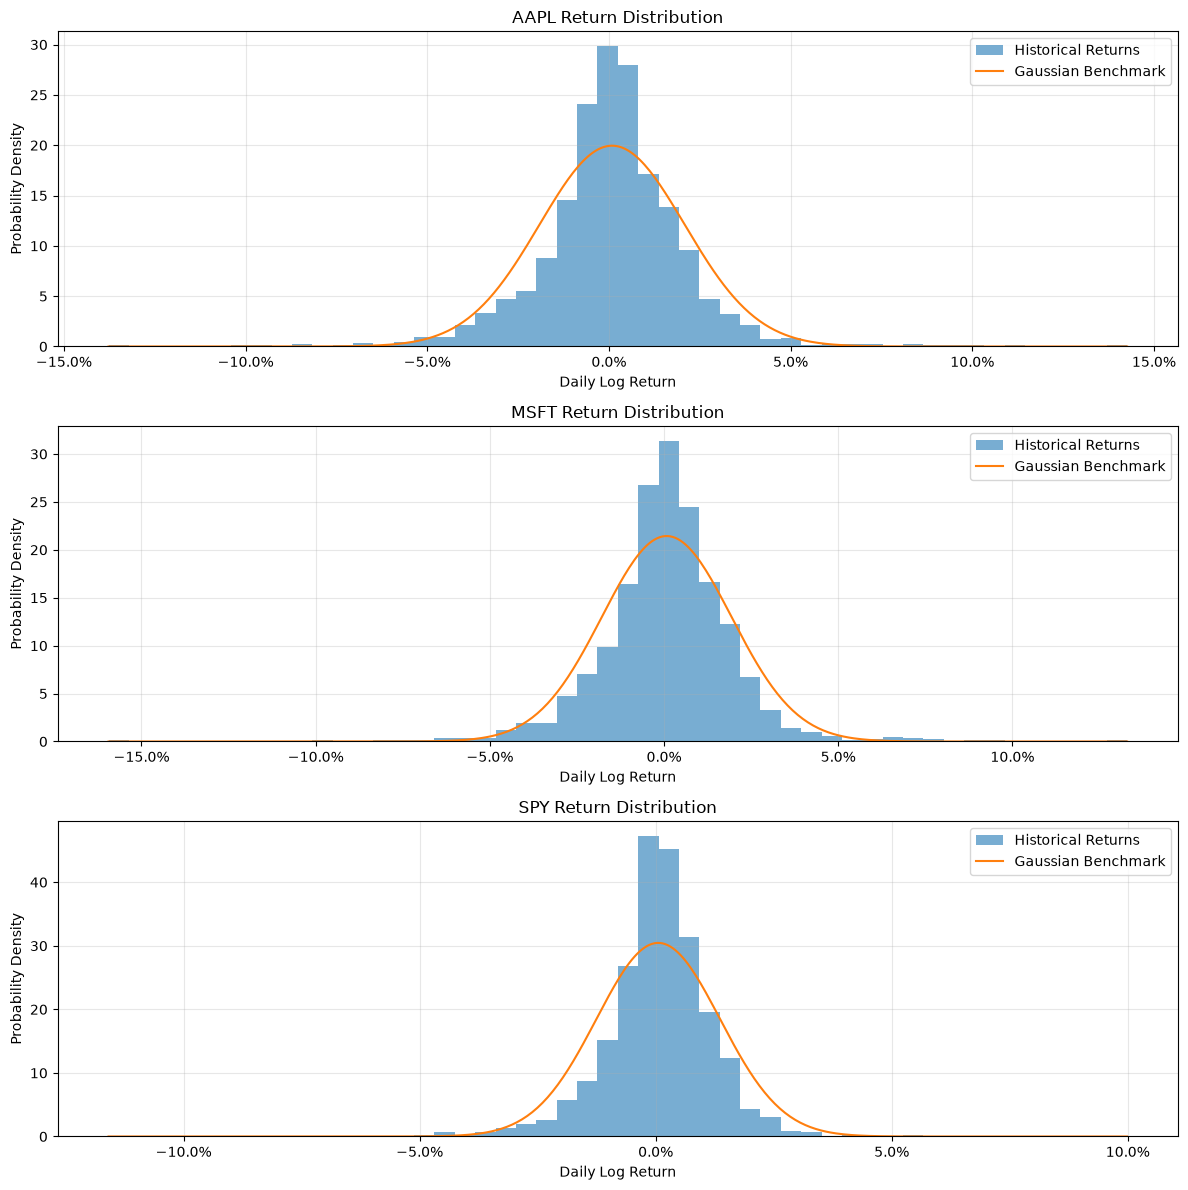

In [5]:
# Plot historical log return distributions with Gaussian benchmarks
fig, axes = plot_return_distributions(data,tickers,return_field="Log Return",bins=50)

## 4. Gaussian Q-Q Analysis

We compare empirical return quantiles against theoretical Gaussian quantiles to investigate deviations from normality, particularly in the extreme tails.

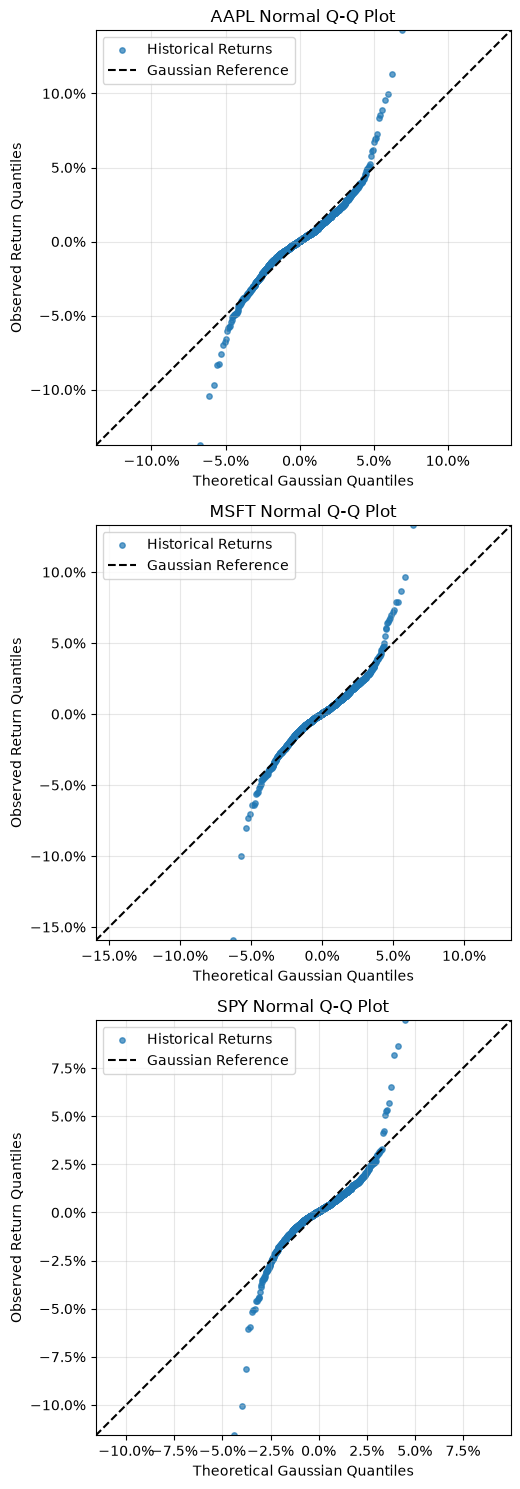

In [6]:
# Compare empirical return quantiles with Gaussian quantiles
fig, axes = plot_return_qq(data,tickers,return_field="Log Return")

### Interpretation of the Empirical Distributions

The descriptive statistics, histograms, and Gaussian Q-Q plots reveal substantial deviations from the normality assumption.

All three assets exhibit positive excess kurtosis, and their empirical return distributions show stronger central concentration and more extreme tail observations than their fitted Gaussian benchmarks.

AAPL is approximately symmetric despite exhibiting heavy tails. MSFT and SPY display negative skewness, with SPY showing the greatest negative asymmetry and excess kurtosis among the three assets.

These findings suggest that Gaussian models may inadequately represent extreme market movements. However, additional statistical testing is needed to evaluate the evidence against normality.

The observed departures may also reflect changes in volatility over time rather than a single stationary return distribution.